In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

path = kagglehub.dataset_download("misrakahmed/vegetable-image-dataset")
base_dir = os.path.join(path, "Vegetable Images")
train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")
val_dir = os.path.join(base_dir, "validation")

C:\Users\Fares\PycharmProjects\PythonProject12\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 534M/534M [03:43<00:00, 2.51MB/s] 

Extracting files...


In [2]:
def count_images(folder):
    counts = {}
    for cls in sorted(os.listdir(folder)):
        cls_path = os.path.join(folder, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts


train_counts = count_images(train_dir)
test_counts = count_images(test_dir)
val_counts = count_images(val_dir)

print(train_counts)
print(test_counts)
print(val_counts)

{'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}
{'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}
{'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


In [3]:
train_df = pd.DataFrame(list(train_counts.items()), columns=["Vegetable", "Train Count"])
test_df = pd.DataFrame(list(test_counts.items()), columns=["Vegetable", "Test Count"])
val_df = pd.DataFrame(list(val_counts.items()), columns=["Vegetable", "Validation Count"])

summary_df = train_df.merge(test_df, on="Vegetable").merge(val_df, on="Vegetable")
print(summary_df)

       Vegetable  Train Count  Test Count  Validation Count
0           Bean         1000         200               200
1   Bitter_Gourd         1000         200               200
2   Bottle_Gourd         1000         200               200
3        Brinjal         1000         200               200
4       Broccoli         1000         200               200
5        Cabbage         1000         200               200
6       Capsicum         1000         200               200
7         Carrot         1000         200               200
8    Cauliflower         1000         200               200
9       Cucumber         1000         200               200
10        Papaya         1000         200               200
11        Potato         1000         200               200
12       Pumpkin         1000         200               200
13        Radish         1000         200               200
14        Tomato         1000         200               200


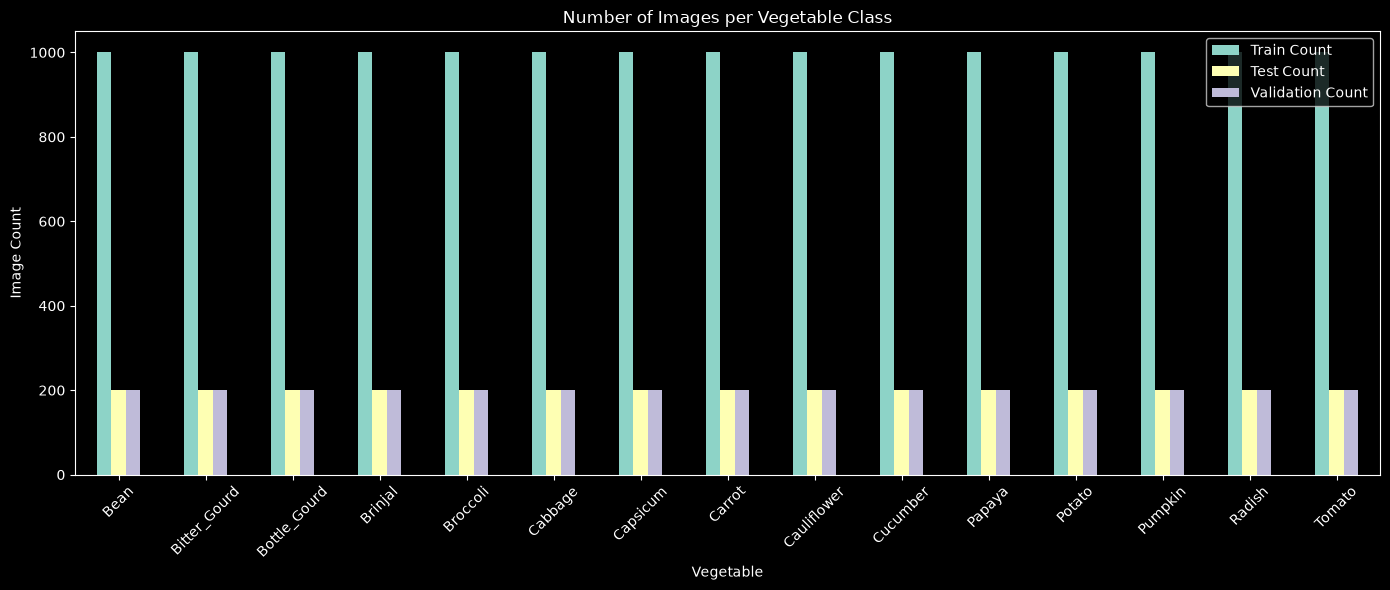

In [4]:
summary_df.set_index("Vegetable").plot(kind="bar", figsize=(14, 6))
plt.title("Number of Images per Vegetable Class")
plt.xlabel("Vegetable")
plt.ylabel("Image Count")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
train_gen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2,
)

val_gen = ImageDataGenerator(rescale=1.0 / 255, validation_split=0.2)

train_ds = train_gen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    seed=42,
)

val_ds = val_gen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    seed=42,
    shuffle=False,
)

Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.


In [6]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 3)),
    MaxPooling2D(),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(),
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(),
    Flatten(),
    Dense(512, activation="relu"),
    Dropout(0.5),
    Dense(15, activation="softmax"),
])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

C:\Users\Fares\PycharmProjects\PythonProject12\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop],
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 197s 521ms/step - accuracy: 0.4693 - loss: 1.5979 - val_accuracy: 0.6833 - val_loss: 0.8706
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 278s 741ms/step - accuracy: 0.7021 - loss: 0.9112 - val_accuracy: 0.8280 - val_loss: 0.5259
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5400s 14s/step - accuracy: 0.7637 - loss: 0.7136 - val_accuracy: 0.9013 - val_loss: 0.3397
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 174s 463ms/step - accuracy: 0.8084 - loss: 0.5901 - val_accuracy: 0.8283 - val_loss: 0.4881
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 181s 482ms/step - accuracy: 0.8363 - loss: 0.5062 - val_accuracy: 0.9287 - val_loss: 0.2327
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 177s 471ms/step - accuracy: 0.8444 - loss: 0.4737 - val_accuracy: 0.8963 - val_loss: 0.3197
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 175s 467ms/step - accuracy: 0.8796 - loss: 0.3801 - val_accuracy: 0.9543 - val_loss: 0.1383
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 175s 466ms/step - accuracy: 0.8821 - 

In [8]:
train_loss, train_acc = model.evaluate(train_ds)
val_loss, val_acc = model.evaluate(val_ds)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Training Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")

375/375 ━━━━━━━━━━━━━━━━━━━━ 97s 258ms/step - accuracy: 0.0662 - loss: 2.7084
94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 80ms/step - accuracy: 0.0677 - loss: 2.7083
Training Accuracy: 0.0662
Validation Accuracy: 0.0677
Training Loss: 2.7084
Validation Loss: 2.7083


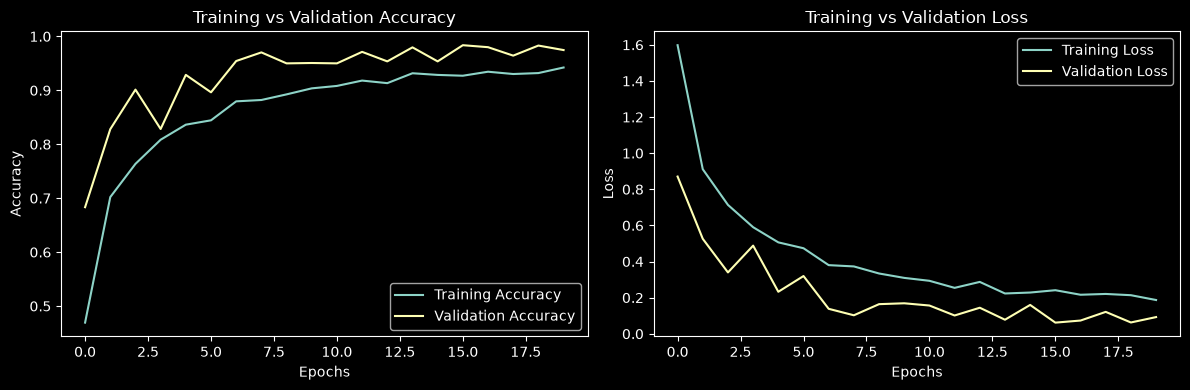

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## Answers

- Balanced? Yes: each class has about the same number of images (1000 train, 200 test, 200 validation), so the model is not biased to any class.
- Convolutional layers: 3. Pooling: reduces feature map size and computation and keeps the important features.
- Dropout: randomly turns off 50% of neurons during training to reduce overfitting.
- Softmax: converts outputs into probabilities over the 15 classes that sum to 1.
- EarlyStopping: stops training when validation loss stops improving, avoiding overfitting and saving time.
- Overfitting: if training accuracy is much higher than validation accuracy, the model is overfitting; a small gap means it generalizes well.